# Ngô Minh Khôi - 6451071037
## Môn học: IT1.231.3 - Khai thác dữ liệu
### Bai5a

### Câu 1

In [1]:
# Ngô Minh Khôi - 6451071037
# Bài 5a - Câu 1: Đọc và lọc dữ liệu hóa đơn nước Đức ('Germany')
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

df_germany = df[df['Country'] == 'Germany'].copy()

print(f"Tổng số giao dịch của khách hàng Đức: {len(df_germany)} dòng")
print("--- 5 dòng đầu tiên của dữ liệu khách hàng Đức ---")
print(df_germany.head())


Ngô Minh Khôi - 6451071037
Tổng số giao dịch của khách hàng Đức: 9042 dòng
--- 5 dòng đầu tiên của dữ liệu khách hàng Đức ---
     InvoiceNo StockCode  ...  CustomerID  Country
1109    536527     22809  ...     12662.0  Germany
1110    536527     84347  ...     12662.0  Germany
1111    536527     84945  ...     12662.0  Germany
1112    536527     22242  ...     12662.0  Germany
1113    536527     22244  ...     12662.0  Germany

[5 rows x 8 columns]


### Câu 2

In [2]:
# Ngô Minh Khôi - 6451071037
# Bài 5a - Câu 2: Gom nhóm Quantity theo InvoiceNo và Description cho nước Đức
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

print(f"Kích thước giỏ hàng nước Đức: {basket_germany.shape} (hóa đơn x mặt hàng)")


Ngô Minh Khôi - 6451071037
Kích thước giỏ hàng nước Đức: (457, 1695) (hóa đơn x mặt hàng)


### Câu 3

In [3]:
# Ngô Minh Khôi - 6451071037
# Bài 5a - Câu 3: Chuyển đổi sang One-hot encoding và loại bỏ cột 'POSTAGE'
import pandas as pd

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

basket_germany_sets = (basket_germany >= 1).astype(int)

if 'POSTAGE' in basket_germany_sets.columns:
    basket_germany_sets = basket_germany_sets.drop(columns=['POSTAGE'])

print(f"Kích thước ma trận One-hot nước Đức sau khi xóa POSTAGE: {basket_germany_sets.shape}")
print("Dữ liệu One-hot mẫu:")
print(basket_germany_sets.iloc[:5, :8])


Ngô Minh Khôi - 6451071037
Kích thước ma trận One-hot nước Đức sau khi xóa POSTAGE: (457, 1694)
Dữ liệu One-hot mẫu:
Description  10 COLOUR SPACEBOY PEN  ...  12 PENCILS TALL TUBE POSY
InvoiceNo                            ...                           
536527                            0  ...                          0
536840                            0  ...                          0
536861                            0  ...                          0
536967                            0  ...                          0
536983                            0  ...                          0

[5 rows x 8 columns]


### Câu 4

In [4]:
# Ngô Minh Khôi - 6451071037
# Bài 5a - Câu 4: Áp dụng thuật toán Apriori với min_sup = 5% cho nước Đức
import pandas as pd
from mlxtend.frequent_patterns import apriori

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

basket_germany_sets = (basket_germany >= 1).astype(int)
if 'POSTAGE' in basket_germany_sets.columns:
    basket_germany_sets = basket_germany_sets.drop(columns=['POSTAGE'])

frequent_itemsets_de = apriori(basket_germany_sets.astype(bool), min_support=0.05, use_colnames=True)
print(f"Tổng số tập phổ biến tìm được với min_sup=5% (Đức): {len(frequent_itemsets_de)}")
print("--- Top 10 tập phổ biến có độ hỗ trợ cao nhất ---")
print(frequent_itemsets_de.sort_values(by='support', ascending=False).head(10))


Ngô Minh Khôi - 6451071037
Tổng số tập phổ biến tìm được với min_sup=5% (Đức): 59
--- Top 10 tập phổ biến có độ hỗ trợ cao nhất ---
     support                                           itemsets
35  0.245077    frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
34  0.157549     frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
24  0.137856      frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
31  0.137856              frozenset({REGENCY CAKESTAND 3 TIER})
56  0.131291  frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,...
48  0.126915                frozenset({WOODLAND CHARLOTTE BAG})
21  0.115974         frozenset({PLASTERS IN TIN CIRCUS PARADE})
22  0.107221              frozenset({PLASTERS IN TIN SPACEBOY})
0   0.102845                frozenset({6 RIBBONS RUSTIC CHARM})
44  0.102845                    frozenset({SPACEBOY LUNCH BOX})


### Câu 5

In [5]:
# Ngô Minh Khôi - 6451071037
# Bài 5a - Câu 5: Tạo luật kết hợp với min_conf = 50% cho nước Đức
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

basket_germany_sets = (basket_germany >= 1).astype(int)
if 'POSTAGE' in basket_germany_sets.columns:
    basket_germany_sets = basket_germany_sets.drop(columns=['POSTAGE'])

frequent_itemsets_de = apriori(basket_germany_sets.astype(bool), min_support=0.05, use_colnames=True)
rules_de = association_rules(frequent_itemsets_de, metric="confidence", min_threshold=0.5)

rules_de["antecedents_str"] = rules_de["antecedents"].apply(lambda x: ', '.join(list(x)))
rules_de["consequents_str"] = rules_de["consequents"].apply(lambda x: ', '.join(list(x)))

print(f"Tổng số luật kết hợp tìm được với min_conf = 50% (Đức): {len(rules_de)}")
print("--- Danh sách các luật kết hợp tìm được ---")
for idx, r in rules_de.iterrows():
    print(f"{r['antecedents_str']} => {r['consequents_str']} [sup: {r['support']:.4f}, conf: {r['confidence']:.4f}, lift: {r['lift']:.4f}]")


Ngô Minh Khôi - 6451071037
Tổng số luật kết hợp tìm được với min_conf = 50% (Đức): 8
--- Danh sách các luật kết hợp tìm được ---
PLASTERS IN TIN CIRCUS PARADE => PLASTERS IN TIN WOODLAND ANIMALS [sup: 0.0678, conf: 0.5849, lift: 4.2429]
PLASTERS IN TIN SPACEBOY => PLASTERS IN TIN WOODLAND ANIMALS [sup: 0.0613, conf: 0.5714, lift: 4.1451]
PLASTERS IN TIN WOODLAND ANIMALS => ROUND SNACK BOXES SET OF4 WOODLAND [sup: 0.0744, conf: 0.5397, lift: 2.2021]
RED RETROSPOT CHARLOTTE BAG => WOODLAND CHARLOTTE BAG [sup: 0.0591, conf: 0.8438, lift: 6.6482]
ROUND SNACK BOXES SET OF4 WOODLAND => ROUND SNACK BOXES SET OF 4 FRUITS [sup: 0.1313, conf: 0.5357, lift: 3.4003]
ROUND SNACK BOXES SET OF 4 FRUITS => ROUND SNACK BOXES SET OF4 WOODLAND [sup: 0.1313, conf: 0.8333, lift: 3.4003]
SPACEBOY LUNCH BOX => ROUND SNACK BOXES SET OF4 WOODLAND [sup: 0.0700, conf: 0.6809, lift: 2.7781]
WOODLAND CHARLOTTE BAG => ROUND SNACK BOXES SET OF4 WOODLAND [sup: 0.0635, conf: 0.5000, lift: 2.0402]


### Câu 6

Ngô Minh Khôi - 6451071037
So sánh thời gian: Apriori: 0.0616s | FP-Growth: 0.0662s
Số lượng tập phổ biến: Apriori = 59 | FP-Growth = 59


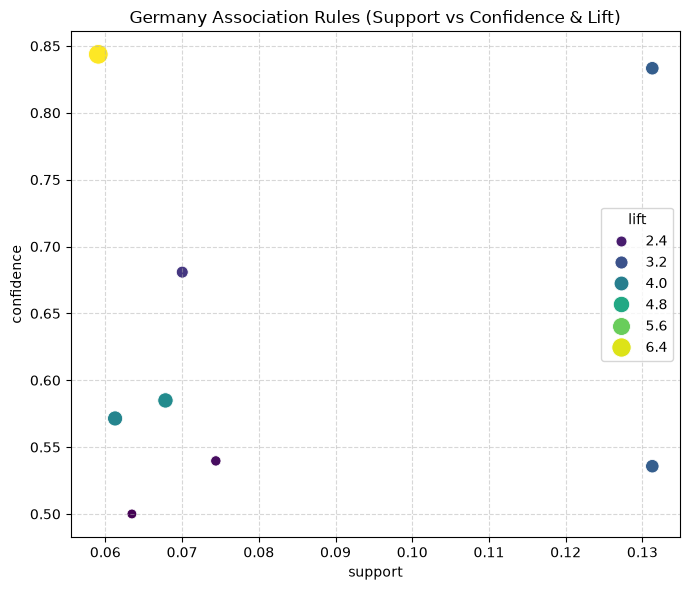

In [6]:
# Ngô Minh Khôi - 6451071037
# Bài 5a - Câu 6: FP-Growth (min_sup=5%, min_conf=50%), scatter plot và so sánh với Apriori
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

print("Ngô Minh Khôi - 6451071037")
df = pd.read_excel(r"dataset/Online Retail.xlsx")
df['Description'] = df['Description'].astype(str).str.strip()
df = df.dropna(subset=['InvoiceNo'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.contains('C')]

basket_germany = (df[df['Country'] == 'Germany']
                  .groupby(['InvoiceNo', 'Description'])['Quantity']
                  .sum().unstack().reset_index().fillna(0)
                  .set_index('InvoiceNo'))

basket_germany_sets = (basket_germany >= 1).astype(int)
if 'POSTAGE' in basket_germany_sets.columns:
    basket_germany_sets = basket_germany_sets.drop(columns=['POSTAGE'])

t0 = time.time()
frequent_ap = apriori(basket_germany_sets.astype(bool), min_support=0.05, use_colnames=True)
t_ap = time.time() - t0

t0 = time.time()
frequent_fp = fpgrowth(basket_germany_sets.astype(bool), min_support=0.05, use_colnames=True)
t_fp = time.time() - t0

rules = association_rules(frequent_fp, metric="confidence", min_threshold=0.5)

plt.figure(figsize=(7, 6))
sns.scatterplot(x='support', y='confidence', size='lift', hue='lift', data=rules, palette='viridis', sizes=(50, 200))
plt.title('Germany Association Rules (Support vs Confidence & Lift)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(r"figures/p2_b5a_t45_c6_germany_rules.png", dpi=150)
plt.show()

print(f"So sánh thời gian: Apriori: {t_ap:.4f}s | FP-Growth: {t_fp:.4f}s")
print(f"Số lượng tập phổ biến: Apriori = {len(frequent_ap)} | FP-Growth = {len(frequent_fp)}")
